# Praktikum 3

## Prediksi harga rumah dengan data dummy

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

In [2]:
# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]
# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [3]:
# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

In [4]:
bobot_awal = model.get_weights()

In [5]:
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)


Epoch 1/100

1/1 [==============================] - 1s 554ms/step - loss: 1.6186
Epoch 2/100
1/1 [==============================] - 0s 8ms/step - loss: 1.6029
Epoch 3/100
1/1 [==============================] - 0s 5ms/step - loss: 1.5872
Epoch 4/100
1/1 [==============================] - 0s 6ms/step - loss: 1.5717
Epoch 5/100
1/1 [==============================] - 0s 0s/step - loss: 1.5563
Epoch 6/100
1/1 [==============================] - 0s 9ms/step - loss: 1.5410
Epoch 7/100
1/1 [==============================] - 0s 3ms/step - loss: 1.5258
Epoch 8/100
1/1 [==============================] - 0s 6ms/step - loss: 1.5107
Epoch 9/100
1/1 [==============================] - 0s 0s/step - loss: 1.4957
Epoch 10/100
1/1 [==============================] - 0s 8ms/step - loss: 1.4808
Epoch 11/100
1/1 [==============================] - 0s 5ms/step - loss: 1.4661
Epoch 12/100
1/1 [==============================] - 0s 4ms/step - loss: 1.4515
Epoch 13/100
1/1 [==============================] - 0s 3ms/

In [6]:
hasil = [(0.001, model.history.history['loss'][-1])]

In [7]:
# Evaluasi
print("Prediksi:", model.predict(X_test))

1/1 [==============================] - 0s 71ms/step
Prediksi: [[0.15013325]]


## Tugas 4

Bandingkan loss pada learning rate 0.001, 0.01, dan 0.1.

In [8]:
for learning_rate in [0.01, 0.1]:
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    model.set_weights(bobot_awal)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mse')
    h = model.fit(X_train, y_train, epochs=100)
    hasil.append((learning_rate, h.history['loss'][-1]))

print(f"{'Learning rate':>14} {'Loss latih akhir':>18}")
for learning_rate, loss_akhir in hasil:
    print(f"{learning_rate:>14.3f} {loss_akhir:>18.6f}")

Epoch 1/100
1/1 [==============================] - 0s 449ms/step - loss: 1.6186
Epoch 2/100
1/1 [==============================] - 0s 4ms/step - loss: 1.4658
Epoch 3/100
1/1 [==============================] - 0s 5ms/step - loss: 1.3240
Epoch 4/100
1/1 [==============================] - 0s 5ms/step - loss: 1.1943
Epoch 5/100
1/1 [==============================] - 0s 4ms/step - loss: 1.0744
Epoch 6/100
1/1 [==============================] - 0s 4ms/step - loss: 0.9642
Epoch 7/100
1/1 [==============================] - 0s 3ms/step - loss: 0.8635
Epoch 8/100
1/1 [==============================] - 0s 4ms/step - loss: 0.7719
Epoch 9/100
1/1 [==============================] - 0s 4ms/step - loss: 0.6891
Epoch 10/100
1/1 [==============================] - 0s 3ms/step - loss: 0.6144
Epoch 11/100
1/1 [==============================] - 0s 4ms/step - loss: 0.5474
Epoch 12/100
1/1 [==============================] - 0s 3ms/step - loss: 0.4875
Epoch 13/100
1/1 [==============================] - 0s 7ms/

Bobot awal dan pembagian data disamakan pada ketiga percobaan learning rate.

## Prediksi harga rumah dengan data Boston

In [9]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_boston
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

In [10]:
# 1. Load
data = load_boston()
X = data.data; y = data.target

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

e:\Code\machine_learning\js13\dataset_js\.venv\Lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function load_boston is deprecated; `load_boston` is deprecated in 1.0 and will be removed in 1.2.

    The Boston housing prices dataset has an ethical problem. You can refer to
    the documentation of this function for further details.

    The scikit-learn maintainers therefore strongly discourage the use of this
    dataset unless the purpose of the code is to study and educate about
    ethical issues in data science and machine learning.

    In this special case, you can fetch the dataset from the original
    source::

        import pandas as pd
        import numpy as np

        data_url = "http://lib.stat.cmu.edu/datasets/boston"
        raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
        data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
        target = raw_df.values[1::2, 2]

    Alternative datasets include the Califor

In [11]:
# 3. Build model
model = Sequential([
Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
Dense(32, activation='relu'),
Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

In [12]:
# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

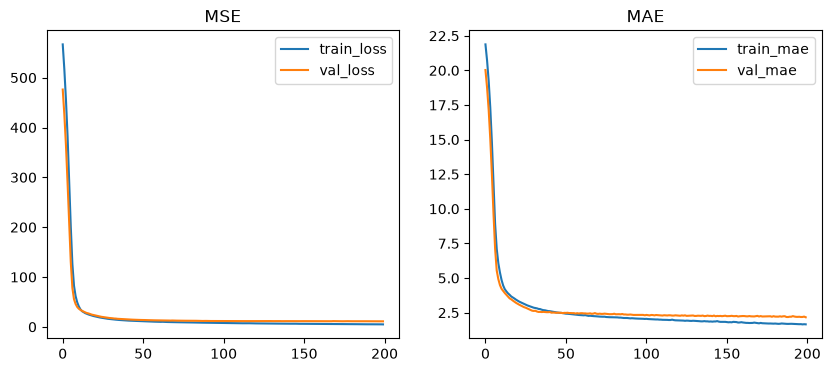

4/4 [==============================] - 0s 1ms/step
RMSE: 3.331544204865865


In [13]:
# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))